In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

# Load the NHANESDS dataset
file_path = '/content/NHANESDS.csv'
df = pd.read_csv(file_path)
df

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,MCQ366A,MCQ366B,MCQ366C,MCQ366D,MCQ371A,MCQ371B,MCQ371C,MCQ371D,OSQ230,SMQ040
0,109263,66,2,1,2,NaN,5,6,2.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,109264,66,2,2,13,NaN,1,1,2.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,109265,66,2,1,2,NaN,3,3,2.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,109266,66,2,2,29,NaN,5,6,2.0,2,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN
4,109267,66,1,2,21,NaN,2,2,NaN,2,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15555,124818,66,2,1,40,NaN,4,4,1.0,1,...,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,NaN
15556,124819,66,2,1,2,NaN,4,4,2.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15557,124820,66,2,2,7,NaN,3,3,2.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15558,124821,66,2,1,63,NaN,4,4,1.0,1,...,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN


In [ ]:
# Step 1: Filter for Black and White population with medicated hypertension
hypertensive_df = df[
    (df['RIDRETH3'].isin([3, 4])) &  # 3: White, 4: Black
    (df['BPQ040A'] == 1) &          # Told to take medication for HBP
    (df['BPQ050A'] == 1)            # Currently taking medication for HBP
]
hypertensive_df

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,MCQ366A,MCQ366B,MCQ366C,MCQ366D,MCQ371A,MCQ371B,MCQ371C,MCQ371D,OSQ230,SMQ040
19,109282,66,2,1,76,NaN,3,3,2.0,1,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,3.0
27,109290,66,2,2,68,NaN,4,4,2.0,1,...,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,NaN
35,109298,66,2,1,68,NaN,3,3,2.0,1,...,1.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,NaN
53,109316,66,2,2,62,NaN,4,4,1.0,1,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,NaN
61,109324,66,2,2,49,NaN,3,3,1.0,1,...,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15533,124796,66,2,2,61,NaN,4,4,2.0,1,...,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,NaN
15536,124799,66,2,2,80,NaN,3,3,1.0,1,...,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,9.0,1.0
15542,124805,66,2,2,66,NaN,4,4,2.0,2,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,NaN
15547,124810,66,2,2,56,NaN,4,4,1.0,1,...,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,NaN


In [ ]:
# Step 2: Filter relevant variables for CVD and kidney health
relevant_columns = [
    'RIDRETH3', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F','KIQ022', 'KIQ480'
]
hypertensive_df = hypertensive_df[relevant_columns]
hypertensive_df

,RIDRETH3,MCQ160B,MCQ160C,MCQ160D,MCQ160E,MCQ160F,KIQ022,KIQ480
19,3,2.0,2.0,2.0,2.0,2.0,2.0,0.0
27,4,2.0,2.0,2.0,2.0,2.0,2.0,2.0
35,3,2.0,2.0,2.0,2.0,2.0,2.0,3.0
53,4,2.0,2.0,2.0,2.0,2.0,2.0,2.0
61,3,2.0,2.0,2.0,2.0,2.0,2.0,2.0
...,...,...,...,...,...,...,...,...
15533,4,2.0,2.0,2.0,2.0,2.0,2.0,3.0
15536,3,2.0,2.0,2.0,2.0,2.0,2.0,1.0
15542,4,2.0,2.0,2.0,2.0,2.0,2.0,NaN
15547,4,2.0,2.0,2.0,2.0,2.0,2.0,4.0


<ipython-input-6-bfc63d690fb4>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hypertensive_df['Ethnicity'] = hypertensive_df['RIDRETH3'].replace({3: 'White', 4: 'Black'})
<ipython-input-6-bfc63d690fb4>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hypertensive_df['Nocturia'] = hypertensive_df['KIQ480'] >= 2
<ipython-input-6-bfc63d690fb4>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats

CVD Proportions by Ethnicity:
              MCQ160B     MCQ160C     MCQ160D     MCQ160E     MCQ160F
Ethnicity                                                            
Black      190.259740  196.969697  202.597403  192.965368  187.662338
White      193.359375  187.597656  196.679688  187.695312  190.234375

Kidney Health Indicators (Weak Kidneys and Nocturia) by Ethnicity:
           Weak_Kidneys   Nocturia
Ethnicity                         
Black         10.691145  50.323974
White          8.886719  41.699219


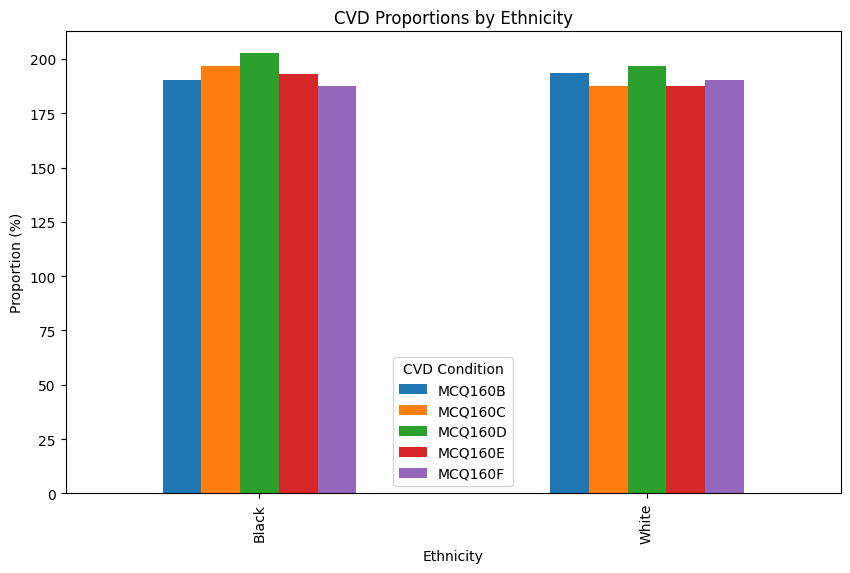

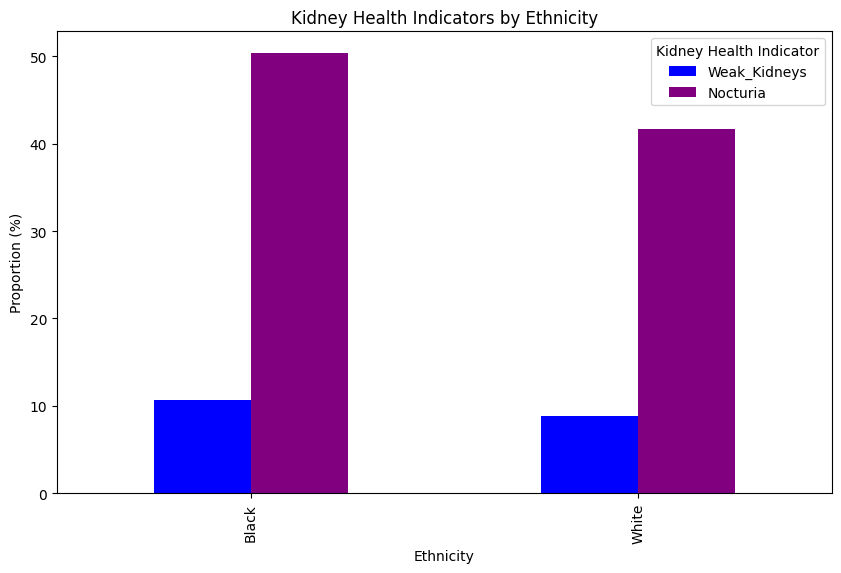

In [ ]:
# Map Ethnicity for readability
hypertensive_df['Ethnicity'] = hypertensive_df['RIDRETH3'].replace({3: 'White', 4: 'Black'})
# Step 3: Define thresholds for kidney health indicators
# Nocturia: waking up 2+ times at night
hypertensive_df['Nocturia'] = hypertensive_df['KIQ480'] >= 2

# Weak/failing kidneys
hypertensive_df['Weak_Kidneys'] = hypertensive_df['KIQ022'] == 1

# Step 4: Calculate proportions of CVD conditions, nocturia, and weak kidneys by ethnicity
cvd_conditions = ['MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F']
cvd_proportions = hypertensive_df.groupby('Ethnicity')[cvd_conditions].mean() * 100
kidney_health_proportions = hypertensive_df.groupby('Ethnicity')[['Weak_Kidneys', 'Nocturia']].mean() * 100

# Display the results
print("CVD Proportions by Ethnicity:")
print(cvd_proportions)

print("\nKidney Health Indicators (Weak Kidneys and Nocturia) by Ethnicity:")
print(kidney_health_proportions)

# Step 5: Plot the results
import matplotlib.pyplot as plt

# Plot CVD Conditions
cvd_proportions.plot(kind='bar', figsize=(10, 6))
plt.title('CVD Proportions by Ethnicity')
plt.ylabel('Proportion (%)')
plt.xlabel('Ethnicity')
plt.legend(title='CVD Condition')
plt.show()

# Plot Kidney Health Indicators
kidney_health_proportions.plot(kind='bar', color=['blue', 'purple'], figsize=(10, 6))
plt.title('Kidney Health Indicators by Ethnicity')
plt.ylabel('Proportion (%)')
plt.xlabel('Ethnicity')
plt.legend(title='Kidney Health Indicator')
plt.show()

In [ ]:
# Map Ethnicity for readability
hypertensive_df['Ethnicity'] = hypertensive_df['RIDRETH3'].replace({3: 'White', 4: 'Black'})

# Step 3: Define weak/failing kidneys indicator
hypertensive_df['Weak_Kidneys'] = hypertensive_df['KIQ022'] == 1

<ipython-input-7-ec6142242f83>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hypertensive_df['Ethnicity'] = hypertensive_df['RIDRETH3'].replace({3: 'White', 4: 'Black'})
<ipython-input-7-ec6142242f83>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hypertensive_df['Weak_Kidneys'] = hypertensive_df['KIQ022'] == 1


In [ ]:
# Step 3: Define weak/failing kidneys indicator
hypertensive_df['Weak_Kidneys'] = hypertensive_df['KIQ022'] == 1

<ipython-input-8-7ca5a7080b15>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hypertensive_df['Weak_Kidneys'] = hypertensive_df['KIQ022'] == 1


In [ ]:
# Step 4: Calculate proportions of CVD conditions and weak kidneys by ethnicity
cvd_conditions = ['MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F']
cvd_proportions = hypertensive_df.groupby('Ethnicity')[cvd_conditions].mean() * 100
kidney_health_proportions = hypertensive_df.groupby('Ethnicity')['Weak_Kidneys'].mean() * 100
kidney_health_proportions

,Weak_Kidneys
Ethnicity,
Black,10.691145
White,8.886719


CVD Proportions by Ethnicity:
              MCQ160B     MCQ160C     MCQ160D     MCQ160E     MCQ160F
Ethnicity                                                            
Black      190.259740  196.969697  202.597403  192.965368  187.662338
White      193.359375  187.597656  196.679688  187.695312  190.234375

Proportion of Participants with Weak/Failing Kidneys by Ethnicity:
Ethnicity
Black    10.691145
White     8.886719
Name: Weak_Kidneys, dtype: float64


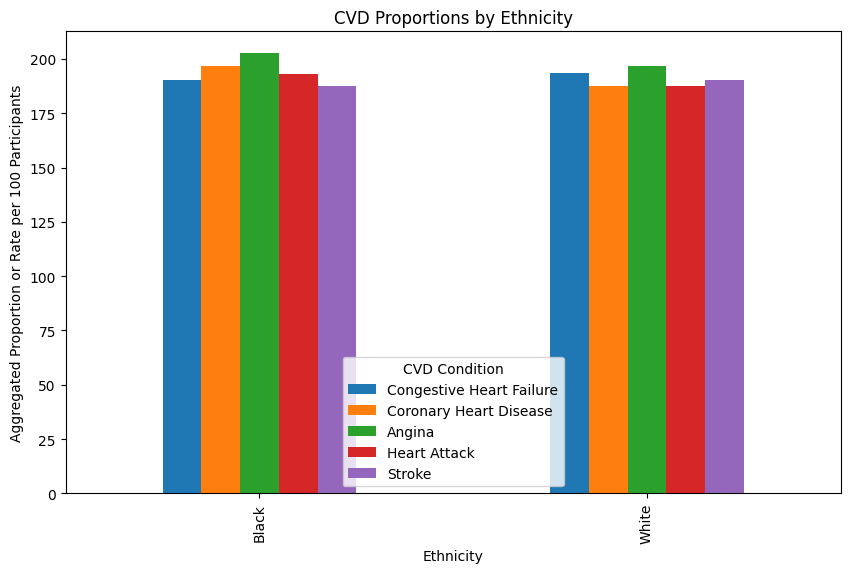

<Figure size 640x480 with 0 Axes>

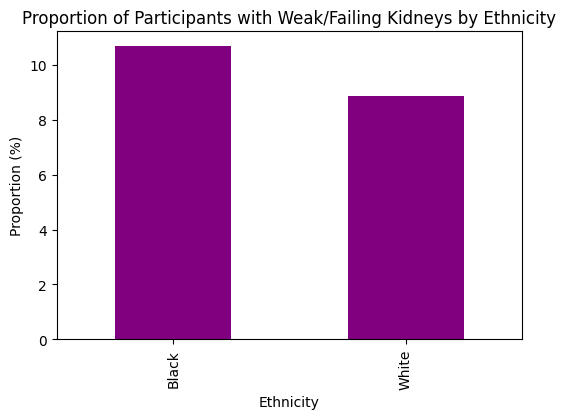

In [ ]:
# Display the results
print("CVD Proportions by Ethnicity:")
print(cvd_proportions)

print("\nProportion of Participants with Weak/Failing Kidneys by Ethnicity:")
print(kidney_health_proportions)

# Plot the results
import matplotlib.pyplot as plt

# Define a dictionary to map codes to condition names
condition_names = {
    'MCQ160B': 'Congestive Heart Failure',
    'MCQ160C': 'Coronary Heart Disease',
    'MCQ160D': 'Angina',
    'MCQ160E': 'Heart Attack',
    'MCQ160F': 'Stroke'
}

# Rename the columns in the DataFrame to use condition names
cvd_proportions = cvd_proportions.rename(columns=condition_names)

# Plot CVD Conditions with updated legend
cvd_proportions.plot(kind='bar', figsize=(10, 6))
plt.title('CVD Proportions by Ethnicity')
plt.ylabel('Aggregated Proportion or Rate per 100 Participants')
plt.xlabel('Ethnicity')
plt.legend(title='CVD Condition')
plt.show()


# Adjust layout to prevent clipping of labels and legend
plt.tight_layout()

# Display plot
plt.show()

# Plot Weak Kidneys Indicator
kidney_health_proportions.plot(kind='bar', color='purple', figsize=(6, 4))
plt.title('Proportion of Participants with Weak/Failing Kidneys by Ethnicity')
plt.ylabel('Proportion (%)')
plt.xlabel('Ethnicity')
plt.show()

Uncontrolled Hypertension by Gender and Ethnicity:
          Ethnicity  Gender  Count
0             Black  Female    529
1             Black    Male    397
2  Mexican American  Female    100
3  Mexican American    Male    113
4    Other Hispanic  Female    134
5    Other Hispanic    Male    117
6             White  Female    509
7             White    Male    515


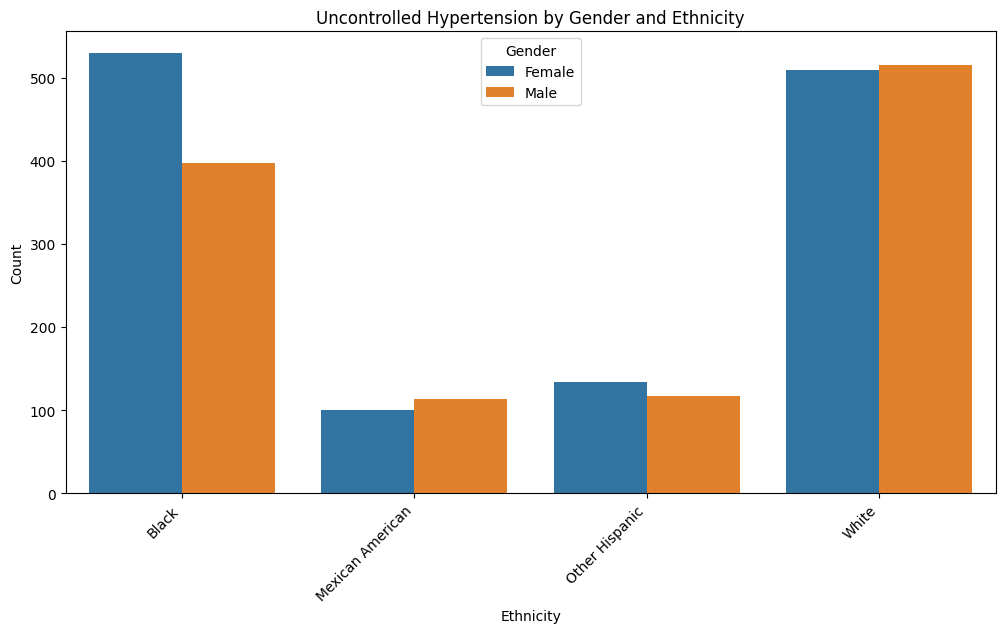

In [ ]:
# Filter the dataset for patients with high blood pressure taking medication
# BPQ040A: Ever told to take prescribed medicine for high blood pressure
# BPQ050A: Currently taking prescribed medicine for high blood pressure
uncontrolled_df = df[(df['BPQ040A'] == 1) & (df['BPQ050A'] == 1)]

# Map the gender and ethnicity variables for readability
uncontrolled_df = uncontrolled_df[~uncontrolled_df['RIDRETH3'].isin([6, 7])]

uncontrolled_df['Gender'] = uncontrolled_df['RIAGENDR'].replace({1: 'Male', 2: 'Female'})
uncontrolled_df['Ethnicity'] = uncontrolled_df['RIDRETH3'].replace({
    1: 'Mexican American',
    2: 'Other Hispanic',
    3: 'White',
    4: 'Black',
     # - Including Multi-Racial
})

# Count the occurrences of uncontrolled hypertension by gender and ethnicity
uncontrolled_counts = uncontrolled_df.groupby(['Ethnicity', 'Gender']).size().reset_index(name='Count')

# Display the data for verification
print("Uncontrolled Hypertension by Gender and Ethnicity:")
print(uncontrolled_counts)

# Plot the results
plt.figure(figsize=(12, 6))
sns.barplot(data=uncontrolled_counts, x='Ethnicity', y='Count', hue='Gender')
plt.title("Uncontrolled Hypertension by Gender and Ethnicity")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Count")
plt.show()

In [ ]:
df = df[~df['RIDRETH3'].isin([6, 7])]


In [ ]:
df['RIDRETH3'] = df['RIDRETH3'].replace({1: 'Mexican American', 2: 'Hispanic', 3: 'White', 4: 'Black'})

<ipython-input-13-692bc4ce79d5>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['RIDRETH3'] = df['RIDRETH3'].replace({1: 'Mexican American', 2: 'Hispanic', 3: 'White', 4: 'Black'})


In [ ]:
'''allowed_val = [1, 2, 3, 4]
df = df.loc[df['RIDRETH3'].isin(allowed_val)]

df.RIDRETH3.value_counts()
'''

"allowed_val = [1, 2, 3, 4]\ndf = df.loc[df['RIDRETH3'].isin(allowed_val)]\n\ndf.RIDRETH3.value_counts()\n"

In [ ]:
df.RIDRETH3.value_counts()

,count
RIDRETH3,
White,5271
Black,4098
Mexican American,1990
Hispanic,1544


In [ ]:
df = df.dropna()
df

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,MCQ366A,MCQ366B,MCQ366C,MCQ366D,MCQ371A,MCQ371B,MCQ371C,MCQ371D,OSQ230,SMQ040


In [ ]:
URDACT_THRESHOLD = 30  # Example threshold for URDACT (mg/g) – adjust based on clinical guidelines
ALBUMIN_THRESHOLD = 30  # Example threshold for albumin (mg/L) – adjust based on clinical guidelines

# Create indicators for elevated URDACT and albumin levels
uncontrolled_df['Elevated_URDACT'] = uncontrolled_df['URDACT'] > URDACT_THRESHOLD
uncontrolled_df['Elevated_Albumin'] = uncontrolled_df['URXUMA'] > ALBUMIN_THRESHOLD


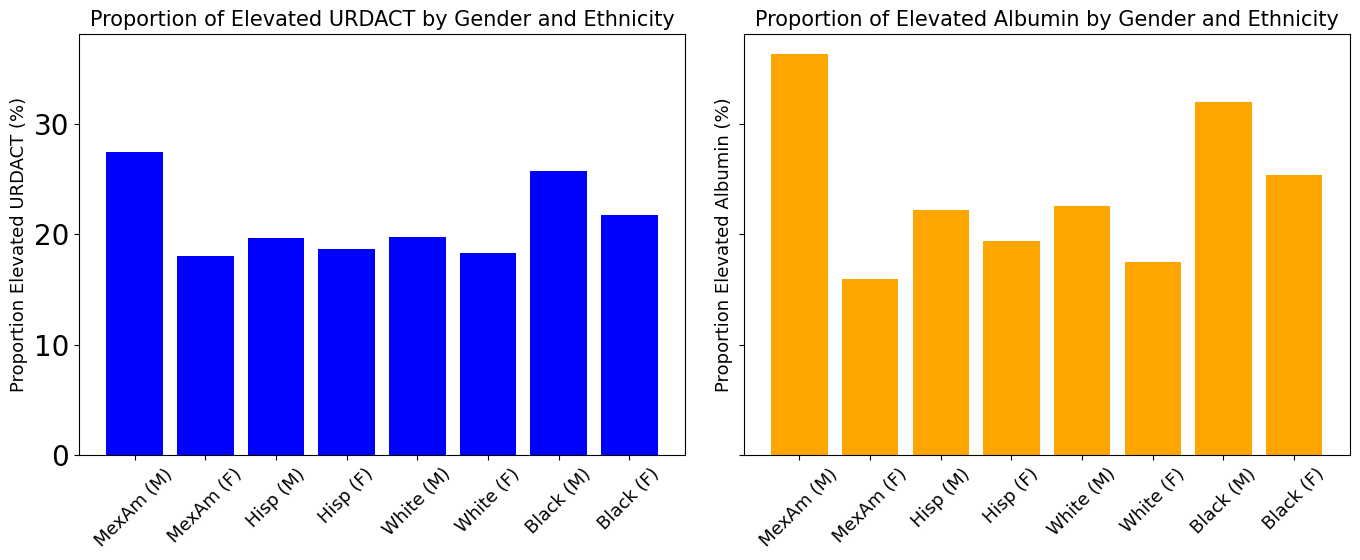

Proportion of Elevated URDACT and Albumin by Gender and Ethnicity:
  Ethnicity Gender  Proportion_Elevated_URDACT  Proportion_Elevated_Albumin
0     MexAm      M                    0.274336                     0.362832
1     MexAm      F                    0.180000                     0.160000
2      Hisp      M                    0.196581                     0.222222
3      Hisp      F                    0.186567                     0.194030
4     White      M                    0.198058                     0.225243
5     White      F                    0.182711                     0.174853
6     Black      M                    0.256927                     0.319899
7     Black      F                    0.217391                     0.253308


In [ ]:
# Define threshold values for elevated URDACT and albumin levels
URDACT_THRESHOLD = 30  # Example threshold for URDACT (mg/g) – adjust based on clinical guidelines
ALBUMIN_THRESHOLD = 30  # Example threshold for albumin (mg/L) – adjust based on clinical guidelines

# Create indicators for elevated URDACT and albumin levels
uncontrolled_df['Elevated_URDACT'] = uncontrolled_df['URDACT'] > URDACT_THRESHOLD
uncontrolled_df['Elevated_Albumin'] = uncontrolled_df['URXUMA'] > ALBUMIN_THRESHOLD

# Group by ethnicity and gender to calculate proportions with elevated levels
elevated_ckd_risk = uncontrolled_df.groupby(['RIDRETH3', 'RIAGENDR']).agg(
    Proportion_Elevated_URDACT=('Elevated_URDACT', 'mean'),
    Proportion_Elevated_Albumin=('Elevated_Albumin', 'mean')
).reset_index()

# Map ethnicity and gender codes to readable labels
ethnicity_map = {1: 'MexAm', 2: 'Hisp', 3: 'White',
                 4: 'Black'}
gender_map = {1: 'M', 2: 'F'}
elevated_ckd_risk['Ethnicity'] = elevated_ckd_risk['RIDRETH3'].map(ethnicity_map)
elevated_ckd_risk['Gender'] = elevated_ckd_risk['RIAGENDR'].map(gender_map)

# Plot the proportions of elevated URDACT and Albumin by Ethnicity and Gender
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Create x-axis labels as a list of strings
x_labels = (elevated_ckd_risk['Ethnicity'] + ' (' + elevated_ckd_risk['Gender'].astype(str) + ')').astype(str).to_list()

# Plot for Elevated URDACT
axes[0].bar(x_labels,
            elevated_ckd_risk['Proportion_Elevated_URDACT'] * 100, color='blue')
axes[0].set_title('Proportion of Elevated URDACT by Gender and Ethnicity', fontsize = 15)
axes[0].set_ylabel('Proportion Elevated URDACT (%)', fontsize = 13)
axes[0].tick_params(axis='x', rotation=45, labelsize = 13) # Added ha='right' for better label visibility

# Plot for Elevated Albumin
axes[1].bar(x_labels,
            elevated_ckd_risk['Proportion_Elevated_Albumin'] * 100, color='orange')
axes[1].set_title('Proportion of Elevated Albumin by Gender and Ethnicity', fontsize = 15)
axes[1].set_ylabel('Proportion Elevated Albumin (%)', fontsize = 13)
axes[1].tick_params(axis='x', rotation=45, labelsize = 13)  # Added ha='right' for better label visibility

plt.tight_layout()
plt.show()

# Display the results in a table format
print("Proportion of Elevated URDACT and Albumin by Gender and Ethnicity:")
print(elevated_ckd_risk[['Ethnicity', 'Gender', 'Proportion_Elevated_URDACT', 'Proportion_Elevated_Albumin']])

Figure 1

Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity:
                  Heart Attack  Heart Attack     Stroke    Stroke  \
White                56.451613           NaN  42.907801       NaN   
Black                29.032258           NaN  42.907801       NaN   
Other Hispanic        9.677419           NaN   7.801418       NaN   
Mexican American      4.838710           NaN   6.382979       NaN   
Male                       NaN     68.548387        NaN  47.51773   
Female                     NaN     31.451613        NaN  52.48227   

                  Congestive Heart Failure  Congestive Heart Failure  \
White                            46.025105                       NaN   
Black                            40.585774                       NaN   
Other Hispanic                    8.368201                       NaN   
Mexican American                  5.020921                       NaN   
Male                                   NaN                 56.485356   
Female    

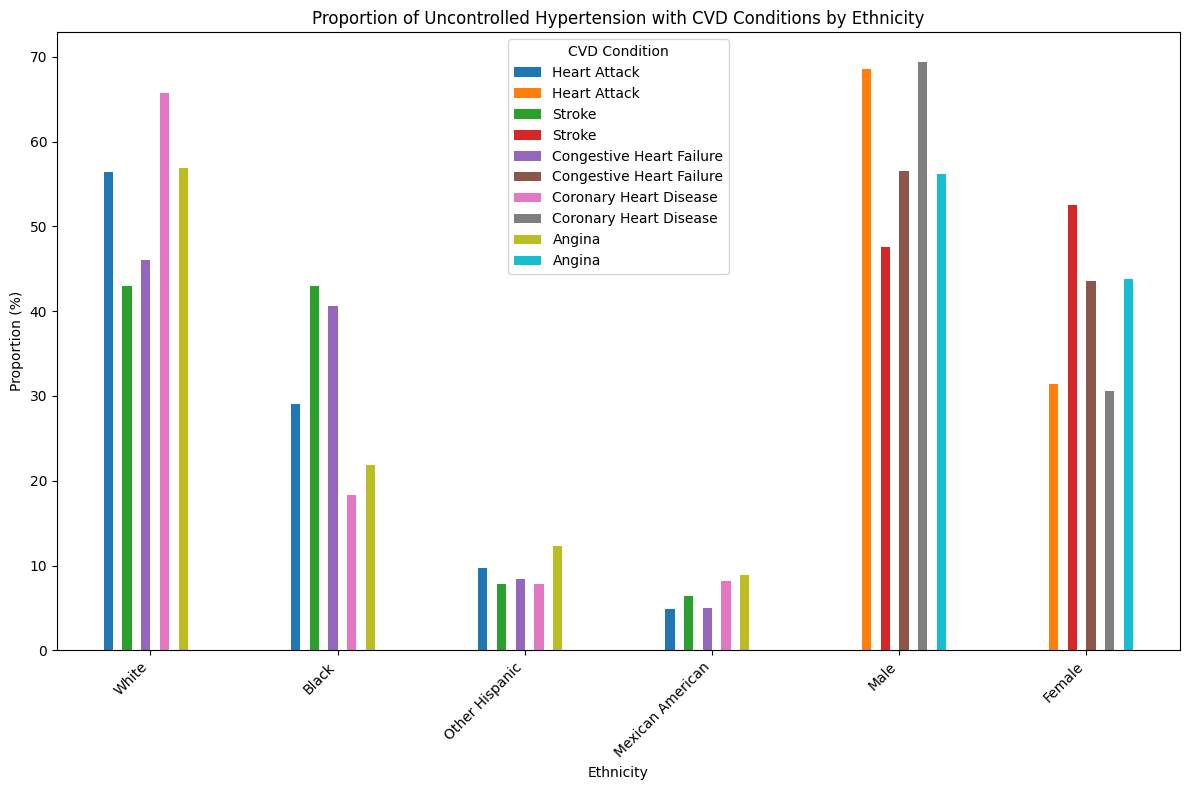

In [ ]:
# List of CVD conditions and their corresponding columns in the dataset

cvd_conditions = {
    'Heart Attack': 'MCQ160E',
    'Stroke': 'MCQ160F',
    'Congestive Heart Failure': 'MCQ160B',
    'Coronary Heart Disease': 'MCQ160C',
    'Angina': 'MCQ160D'
}


# Initialize an empty DataFrame to store the results
cvd_results = pd.DataFrame()

# Loop through each CVD condition
for condition, column in cvd_conditions.items():
    # Filter for patients with the specific CVD condition
    condition_df = uncontrolled_df[uncontrolled_df[column] == 1]

    # Calculate the proportion of each ethnicity with uncontrolled hypertension and the specific CVD condition

    elevated_ckd_risk['Ethnicity'] = elevated_ckd_risk['RIDRETH3'].map(ethnicity_map)
    elevated_ckd_risk['Gender'] = elevated_ckd_risk['RIAGENDR'].map(gender_map)

# Create x-axis labels as a list of strings
    x_labels = (elevated_ckd_risk['Ethnicity'] + ' (' + elevated_ckd_risk['Gender'].astype(str) + ')').astype(str).to_list()
    proportion_by_sex = condition_df['Gender'].value_counts(normalize=True) * 100
    proportion_by_ethnicity = condition_df['Ethnicity'].value_counts(normalize=True) * 100
    proportion_by_ethnicity = proportion_by_ethnicity.rename(condition)
    proportion_by_sex = proportion_by_sex.rename(condition)

    # Append to the results DataFrame
    cvd_results = pd.concat([cvd_results, proportion_by_ethnicity, proportion_by_sex], axis=1)

# Display the results
print("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity:")
print(cvd_results)

# Plot the results
cvd_results.plot(kind='bar', figsize=(12, 8))
plt.title("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity")
plt.ylabel("Proportion (%)")
plt.xlabel("Ethnicity")
plt.legend(title="CVD Condition")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity and Gender:
                           Heart Attack     Stroke  Congestive Heart Failure  \
White (Male)                  41.532258  19.858156                 29.707113   
Black (Male)                  17.338710  20.212766                 20.920502   
White (Female)                14.919355  23.049645                 16.317992   
Black (Female)                11.693548  22.695035                 19.665272   
Hispanic (Male)                6.854839   3.191489                  4.184100   
Hispanic (Female)              2.822581   4.609929                  4.184100   
Mexican American (Male)        2.822581   4.255319                  1.673640   
Mexican American (Female)      2.016129   2.127660                  3.347280   

                           Coronary Heart Disease     Angina  
White (Male)                            47.761194  36.301370  
Black (Male)                            10.447761   8.904110  
White

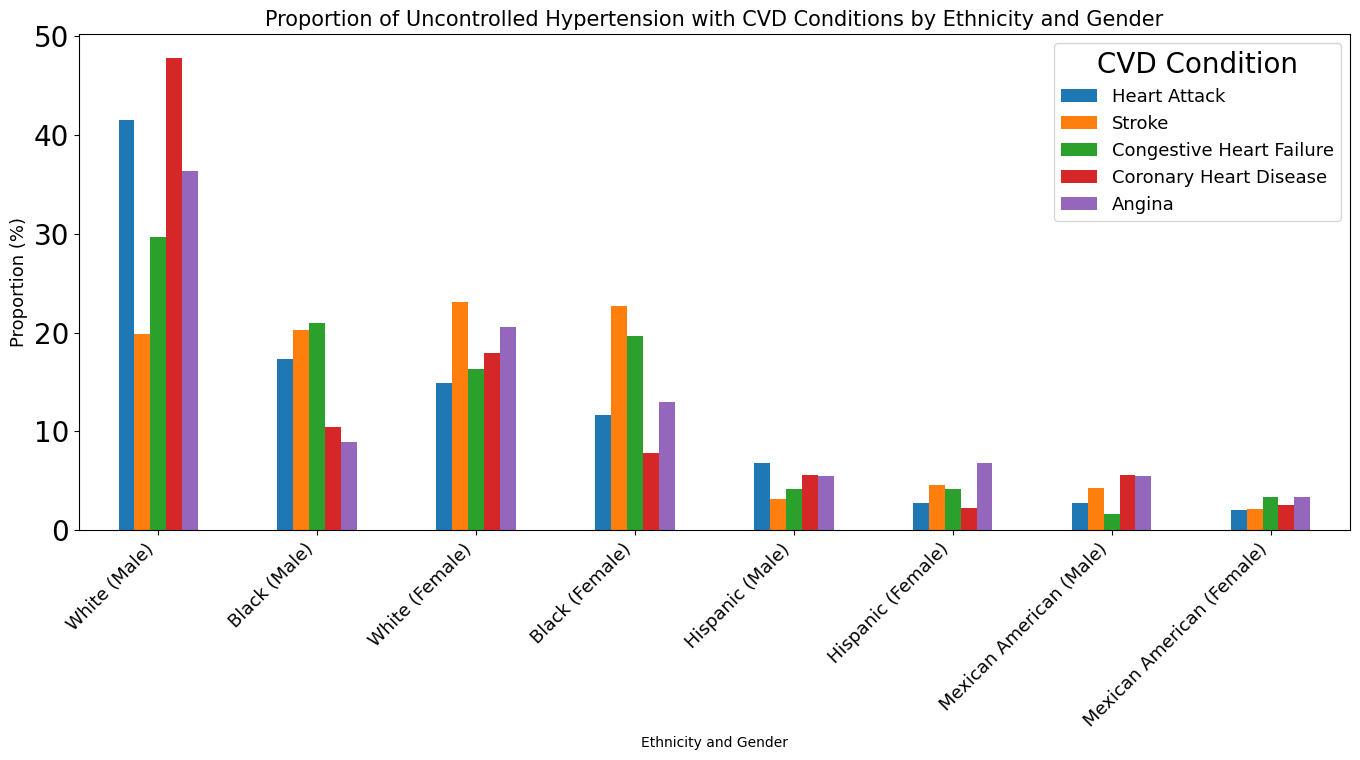

In [ ]:
cvd_conditions = {
    'Heart Attack': 'MCQ160E',
    'Stroke': 'MCQ160F',
    'Congestive Heart Failure': 'MCQ160B',
    'Coronary Heart Disease': 'MCQ160C',
    'Angina': 'MCQ160D'
}

# Initialize an empty DataFrame to store the results
cvd_results = pd.DataFrame()

# Loop through each CVD condition
for condition, column in cvd_conditions.items():
    # Filter for patients with the specific CVD condition
    condition_df = uncontrolled_df[uncontrolled_df[column] == 1].copy()

    # Map ethnicity and gender
    condition_df['Ethnicity'] = condition_df['RIDRETH3'].map(ethnicity_map)
    condition_df['Gender'] = condition_df['RIAGENDR'].map(gender_map)

    # Combine Ethnicity and Gender into one category
    condition_df['Ethnicity-Gender'] = condition_df['Ethnicity'] + ' (' + condition_df['Gender'] + ')'

    # Calculate the proportion for each ethnicity-gender group
    proportion_by_ethnicity_gender = (
        condition_df['Ethnicity-Gender'].value_counts(normalize=True) * 100
    ).rename(condition)

    # Append to the results DataFrame
    cvd_results = pd.concat([cvd_results, proportion_by_ethnicity_gender], axis=1)

# Display the results
print("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity and Gender:")
print(cvd_results)

# Plot the results
cvd_results.plot(kind='bar', figsize=(14, 8))
plt.title("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity and Gender", fontsize = 15)
plt.ylabel("Proportion (%)", fontsize = 13)
plt.xlabel("Ethnicity and Gender", fontsize = 10)
plt.legend(title="CVD Condition", fontsize = 13)
plt.xticks(rotation=45, ha="right", fontsize = 13)
plt.tight_layout()
plt.show()

In [ ]:
URDACT = {
    'Heart Attack': 'MCQ160E',
    'Stroke': 'MCQ160F',
    'Congestive Heart Failure': 'MCQ160B',
    'Coronary Heart Disease': 'MCQ160C',
    'Angina': 'MCQ160D'
}

# Initialize an empty DataFrame to store the results
cvd_results = pd.DataFrame()

# Loop through each CVD condition
for condition, column in cvd_conditions.items():
    # Filter for patients with the specific CVD condition
    condition_df = uncontrolled_df[uncontrolled_df[column] == 1].copy()

    # Map ethnicity and gender
    condition_df['Ethnicity'] = condition_df['RIDRETH3'].map(ethnicity_map)
    condition_df['Gender'] = condition_df['RIAGENDR'].map(gender_map)

    # Combine Ethnicity and Gender into one category
    condition_df['Ethnicity-Gender'] = condition_df['Ethnicity'] + ' (' + condition_df['Gender'] + ')'

    # Calculate the proportion for each ethnicity-gender group
    proportion_by_ethnicity_gender = (
        condition_df['Ethnicity-Gender'].value_counts(normalize=True) * 100
    ).rename(condition)

    # Append to the results DataFrame
    cvd_results = pd.concat([cvd_results, proportion_by_ethnicity_gender], axis=1)

# Display the results
print("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity and Gender:")
print(cvd_results)

# Plot the results
cvd_results.plot(kind='bar', figsize=(14, 8))
plt.title("Proportion of Uncontrolled Hypertension with CVD Conditions by Ethnicity and Gender")
plt.ylabel("Proportion (%)")
plt.xlabel("Ethnicity and Gender")
plt.legend(title="CVD Condition")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()